# 04 – Article classification

Following the case study approach: **relevant attributes → feature selection → clustering algorithm → evaluation metric**.

1. Population: articles with demand 2019–2021 are clustered; articles **without demand** form a rule-based class
   (their demand features are undefined, they would distort the clustering).
2. Candidate features: inventory-relevant attributes, log-transformed where skewed, standardised.
3. Feature selection: correlation filter + forward selection (silhouette), starting from a domain-driven core
   (value, demand frequency and variability – the dimensions of ABC and Syntetos-Boylan).
4. Algorithms: k-means, Gaussian mixture, hierarchical (Ward), k = 2…10.
5. Evaluation: silhouette (↑), Davies-Bouldin (↓), Calinski-Harabasz (↑), minimum cluster size, bootstrap stability (ARI).
6. Cluster profiles → basis for the strategy per class.

**Output to share:** `outputs/tables/04_classification_summary.txt` + figures.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

sys.path.insert(0, str(Path.cwd().parent))
from src import config as C

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

summary = []
def log(title, obj=""):
    text = obj.to_string() if isinstance(obj, (pd.DataFrame, pd.Series)) else str(obj)
    block = f"\n=== {title} ===\n{text}"
    print(block)
    summary.append(block)

def savefig(name):
    plt.savefig(C.FIGURES / f"{name}.png")
    plt.show()

SEED = 42
DPY = C.DAYS_PER_YEAR
F = pd.read_parquet(C.ARTICLE_FEATURES).set_index("article_nr")
pop = F[F["months_with_demand"] > 0].copy()
log("Population", pd.Series({"inventory articles": len(F), "clustered (demand 2019-2021)": len(pop),
                             "rule-based class 'no demand'": len(F) - len(pop)}))


=== Population ===
inventory articles              1751
clustered (demand 2019-2021)    1498
rule-based class 'no demand'     253


## 1. Candidate features
Clustering describes the **articles** (demand, value, product role), not the current policy we want to evaluate.
Policy outcomes – capital lockup, coverage days, current reorder point ratio, MOQ coverage – are therefore
**not** clustering inputs (that would be circular); they are used to profile the clusters afterwards.
Lead time is also excluded: it is manually maintained with a few standard values (30, 15, 10 days), which would
create artificial clusters; it enters the safety stock formula instead.

In [2]:
X_all = pd.DataFrame({
    "log_consumption_value": np.log1p(pop["consumption_value_12m"]),  # importance (ABC)
    "log_adi":               np.log(pop["adi"]),                       # demand frequency
    "log_cv2":               np.log1p(pop["cv2"]),                     # demand size variability
    "cv":                    pop["cv"].clip(upper=6),                  # monthly variability (XYZ)
    "log_price":             np.log1p(pop["last_direct_cost"]),        # unit value
    "usage_share":           pop["usage_share"].fillna(0),             # production component vs. sales article
    "log_days_since_demand": np.log1p(pop["days_since_demand"]),       # recency
}, index=pop.index)
coverage = pop["lockup_12m"] / (pop["consumption_value_12m"] / DPY).replace(0, np.nan)
log("Candidate features – describe", X_all.describe().T.round(2))


=== Candidate features – describe ===
                        count  mean   std   min   25%   50%   75%    max
log_consumption_value  1498.0  6.36  2.85  0.00  4.58  6.83  8.39  13.53
log_adi                1498.0  0.74  0.83  0.00  0.09  0.45  1.10   3.58
log_cv2                1498.0  0.58  0.36  0.00  0.34  0.53  0.77   2.51
cv                     1498.0  1.78  1.18  0.19  0.96  1.46  2.17   6.00
log_price              1498.0  1.76  1.39  0.00  0.43  1.73  2.72   6.01
usage_share            1498.0  0.60  0.45  0.00  0.00  0.89  1.00   1.00
log_days_since_demand  1498.0  3.12  1.81  0.00  1.39  3.61  4.22   6.97


## 2. Feature selection – step 1: correlation filter (|r| > 0.85)

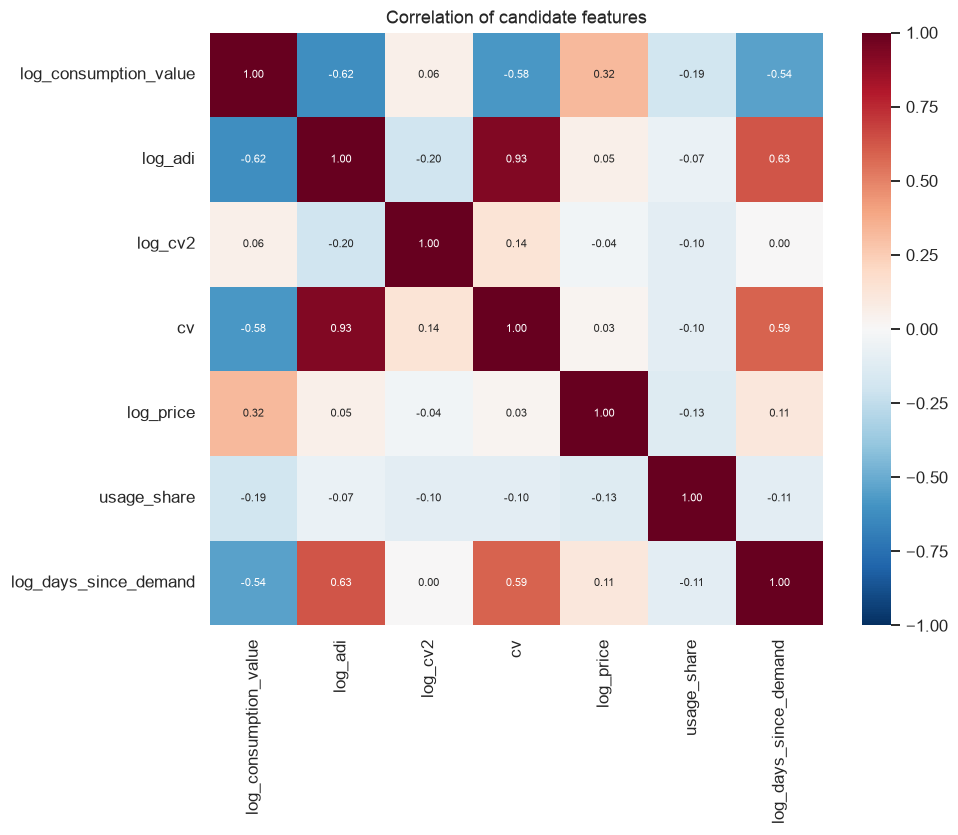


=== Highly correlated pairs ===
         a   b     r
0  log_adi  cv  0.93

=== Dropped by correlation filter ===
['cv']


In [3]:
corr = X_all.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation of candidate features")
savefig("04_feature_correlation")

CORE = ["log_consumption_value", "log_adi", "log_cv2"]   # value (ABC) + frequency & variability (Syntetos-Boylan)
to_drop = set()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
         if abs(corr.loc[a, b]) > 0.85]
for a, b, r in sorted(pairs, key=lambda x: -abs(x[2])):
    if a in to_drop or b in to_drop:
        continue
    cand = [c for c in (a, b) if c not in CORE]
    if not cand:
        continue
    drop = max(cand, key=lambda c: corr[c].abs().mean())
    to_drop.add(drop)
log("Highly correlated pairs", pd.DataFrame(pairs, columns=["a", "b", "r"]).round(2) if pairs else "none")
log("Dropped by correlation filter", sorted(to_drop) or "none")
candidates = [c for c in X_all.columns if c not in to_drop]

## 3. Feature selection – step 2: forward selection
Start from the core (value, demand frequency, demand variability), then add the feature with the best mean
silhouette (k-means, k = 3…6). Silhouette naturally drops when dimensions are added, so the best addition is
always taken until 4 features; beyond that only if the gain is ≥ 0.005 (max. 6).

In [4]:
def mean_silhouette(cols, ks=range(3, 7)):
    Z = StandardScaler().fit_transform(X_all[cols])
    scores = []
    for k in ks:
        lab = KMeans(k, n_init=10, random_state=SEED).fit_predict(Z)
        scores.append(silhouette_score(Z, lab))
    return float(np.mean(scores))

selected = list(CORE)
path = [{"step": 0, "added": "+".join(CORE), "mean_silhouette": mean_silhouette(selected)}]
while len(selected) < 6:
    remaining = [c for c in candidates if c not in selected]
    scores = {c: mean_silhouette(selected + [c]) for c in remaining}
    best = max(scores, key=scores.get)
    gain = scores[best] - path[-1]["mean_silhouette"]
    path.append({"step": len(path), "added": best, "mean_silhouette": scores[best], "gain": gain})
    if len(selected) >= 4 and gain < 0.005:
        path[-1]["added"] += " (rejected)"
        break
    selected.append(best)

log("Forward selection path", pd.DataFrame(path).round(3))
FEATURES = selected
log("Selected features", FEATURES)
X = StandardScaler().fit_transform(X_all[FEATURES])


=== Forward selection path ===
   step                                  added  mean_silhouette   gain
0     0  log_consumption_value+log_adi+log_cv2            0.306    NaN
1     1                            usage_share            0.327  0.021
2     2       log_days_since_demand (rejected)            0.283 -0.044

=== Selected features ===
['log_consumption_value', 'log_adi', 'log_cv2', 'usage_share']


## 4. Algorithms and number of clusters


=== Evaluation metrics ===
algorithm  k  silhouette  davies_bouldin  calinski_harabasz  min_cluster_%
   kmeans  2       0.337           1.281            600.672         22.096
      gmm  2       0.305           1.478            489.435         36.916
     ward  2       0.287           1.528            450.475         37.116
   kmeans  3       0.346           1.119            713.226         18.158
      gmm  3       0.083           3.000            202.552         26.636
     ward  3       0.315           1.220            569.943         13.551
   kmeans  4       0.339           1.107            670.979         14.753
      gmm  4       0.055           2.506            197.296         16.489
     ward  4       0.302           1.316            499.393         10.414
   kmeans  5       0.316           1.149            641.543         10.013
      gmm  5       0.031           2.152            192.263         12.817
     ward  5       0.284           1.183            475.387          9.7

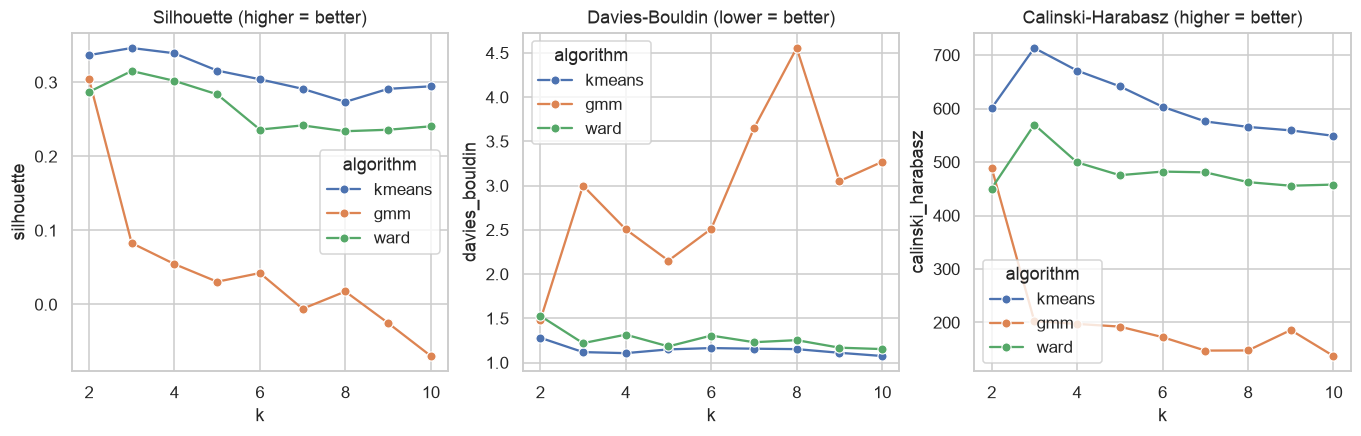

In [5]:
rows = []
for k in range(2, 11):
    models = {
        "kmeans": KMeans(k, n_init=20, random_state=SEED).fit_predict(X),
        "gmm": GaussianMixture(k, covariance_type="full", n_init=3, random_state=SEED).fit(X).predict(X),
        "ward": AgglomerativeClustering(k, linkage="ward").fit_predict(X),
    }
    for name, lab in models.items():
        if len(set(lab)) < 2:
            continue
        rows.append({"algorithm": name, "k": k,
                     "silhouette": silhouette_score(X, lab),
                     "davies_bouldin": davies_bouldin_score(X, lab),
                     "calinski_harabasz": calinski_harabasz_score(X, lab),
                     "min_cluster_%": np.bincount(lab).min() / len(lab) * 100})
evals = pd.DataFrame(rows)
log("Evaluation metrics", evals.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"]):
    sns.lineplot(data=evals, x="k", y=m, hue="algorithm", marker="o", ax=ax)
    ax.set_title(m.replace("_", "-").title() + (" (lower = better)" if m == "davies_bouldin" else " (higher = better)"))
savefig("04_cluster_evaluation")

**Choice of model:** k-means is preferred for interpretability (centroids = typical article per class) and
reproducibility. k is chosen in 3…8 by the best silhouette, requiring every cluster to hold ≥ 3% of articles
(tiny clusters can't carry a strategy). Change `K_OVERRIDE` if the profiles below suggest a better k.

In [6]:
K_OVERRIDE = None
ok = evals[(evals["algorithm"] == "kmeans") & evals["k"].between(3, 8) & (evals["min_cluster_%"] >= 3)]
K = K_OVERRIDE or int(ok.loc[ok["silhouette"].idxmax(), "k"])
log("Chosen k (k-means)", K)
log(f"All algorithms at k = {K}", evals[evals["k"] == K].round(3).to_string(index=False))

km = KMeans(K, n_init=50, random_state=SEED).fit(X)
labels = km.labels_

# Stability: re-cluster 80% bootstrap samples, compare with the full-data labels (ARI)
rng = np.random.default_rng(SEED)
aris = []
for _ in range(30):
    idx = rng.choice(len(X), int(0.8 * len(X)), replace=False)
    lab_b = KMeans(K, n_init=10, random_state=int(rng.integers(1e6))).fit_predict(X[idx])
    aris.append(adjusted_rand_score(labels[idx], lab_b))
log("Bootstrap stability (ARI, 30 runs of 80% samples)", f"mean {np.mean(aris):.3f} | min {np.min(aris):.3f}")

log("Agreement with classic schemes (ARI; 0 = unrelated, 1 = identical)", pd.Series({
    "ABC": adjusted_rand_score(pop["abc"], labels),
    "XYZ": adjusted_rand_score(pop["xyz"], labels),
    "ABC-XYZ": adjusted_rand_score(pop["abc"] + pop["xyz"], labels),
    "demand pattern (Syntetos-Boylan)": adjusted_rand_score(pop["pattern"], labels),
    "product type": adjusted_rand_score(pop["product_type"], labels),
}).round(3))


=== Chosen k (k-means) ===
3

=== All algorithms at k = 3 ===
algorithm  k  silhouette  davies_bouldin  calinski_harabasz  min_cluster_%
   kmeans  3       0.346           1.119            713.226         18.158
      gmm  3       0.083           3.000            202.552         26.636
     ward  3       0.315           1.220            569.943         13.551

=== Bootstrap stability (ARI, 30 runs of 80% samples) ===
mean 0.978 | min 0.947

=== Agreement with classic schemes (ARI; 0 = unrelated, 1 = identical) ===
ABC                                 0.064
XYZ                                -0.036
ABC-XYZ                             0.015
demand pattern (Syntetos-Boylan)    0.068
product type                        0.447


## 5. Cluster profiles
Clusters are numbered by capital lockup (cluster 1 = most capital). Medians on the original scale.


=== Cluster profiles ===
cluster                         C1          C2         C3
articles                    743.00      474.00     281.00
lockup                  2649593.30  1928411.68  234925.84
consumption_value       6406108.90  6351479.93   21415.88
med_consumption_value      1057.82     3171.24      10.16
med_lockup                  732.80      733.27     195.91
med_coverage_days           232.88       93.64    2703.33
med_months_with_demand       29.00       23.00       4.00
med_adi                       1.20        1.50       7.20
med_cv2                       0.70        0.82       0.33
med_cv                        1.19        1.47       3.12
med_lead_time                30.00       15.00      30.00
med_rop_ratio                 3.25        2.30      38.20
med_moq_months                3.87        1.73      54.03
med_usage_share               1.00        0.04       1.00
med_days_since_demand        29.00       35.00     156.00
med_price                     2.88        6.76

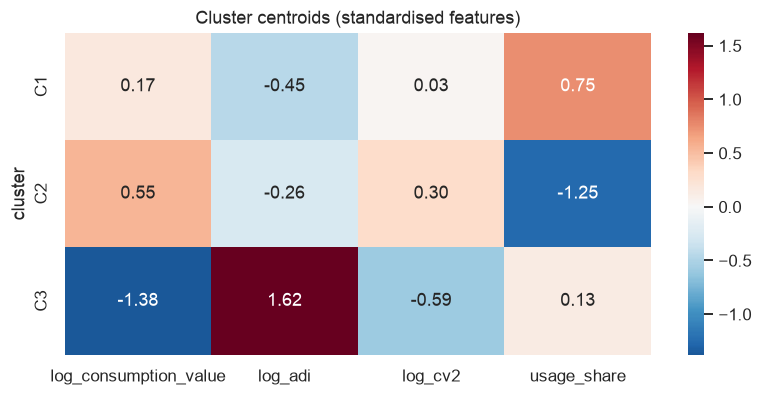

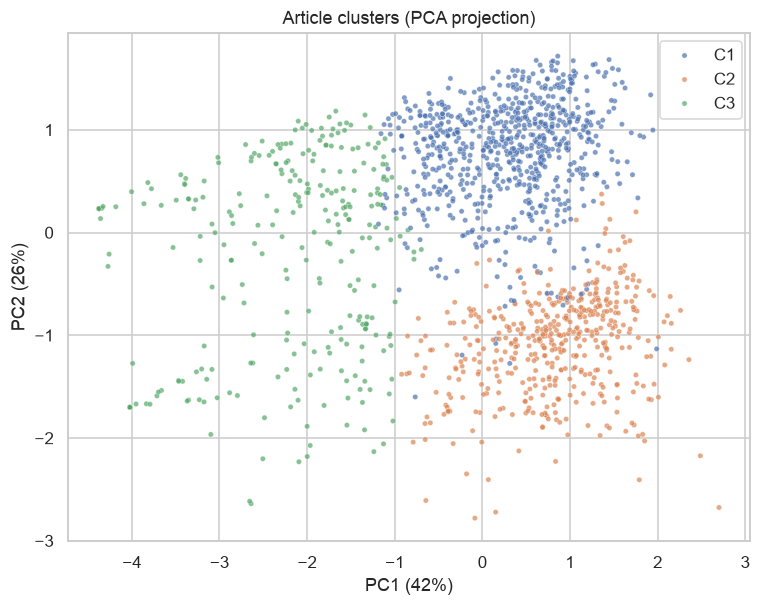


=== PCA loadings ===
                        PC1   PC2
log_consumption_value  0.67  0.06
log_adi               -0.67 -0.30
log_cv2                0.28 -0.40
usage_share           -0.16  0.86


In [7]:
order = pd.Series(pop["lockup_12m"].values).groupby(labels).sum().sort_values(ascending=False).index
relabel = {old: f"C{i + 1}" for i, old in enumerate(order)}
pop["cluster"] = pd.Series(labels, index=pop.index).map(relabel)
pop["coverage_days"] = coverage

total_lockup = F["lockup_12m"].sum()
prof = pop.groupby("cluster").agg(
    articles=("cluster", "size"),
    lockup=("lockup_12m", "sum"),
    consumption_value=("consumption_value_12m", "sum"),
    med_consumption_value=("consumption_value_12m", "median"),
    med_lockup=("lockup_12m", "median"),
    med_coverage_days=("coverage_days", "median"),
    med_months_with_demand=("months_with_demand", "median"),
    med_adi=("adi", "median"),
    med_cv2=("cv2", "median"),
    med_cv=("cv", "median"),
    med_lead_time=("lead_time", "median"),
    med_rop_ratio=("rop_ratio", "median"),
    med_moq_months=("moq_months", "median"),
    med_usage_share=("usage_share", "median"),
    med_days_since_demand=("days_since_demand", "median"),
    med_price=("last_direct_cost", "median"),
)
prof["lockup_share_%"] = prof["lockup"] / total_lockup * 100
prof["coverage_days_total"] = prof["lockup"] / (prof["consumption_value"] / DPY)
log("Cluster profiles", prof.round(2).T)

for col in ["product_type", "abc", "xyz", "pattern"]:
    log(f"Cluster x {col} (% of articles in cluster)",
        (pd.crosstab(pop["cluster"], pop[col], normalize="index") * 100).round(0))

# Standardised centroids heatmap
cent = pd.DataFrame(X, index=pop.index, columns=FEATURES).groupby(pop["cluster"]).mean()
plt.figure(figsize=(1.4 * len(FEATURES) + 3, 0.6 * K + 2))
sns.heatmap(cent, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Cluster centroids (standardised features)")
savefig("04_cluster_centroids")

# PCA view
pc = PCA(2, random_state=SEED).fit(X)
P = pc.transform(X)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=pop["cluster"].values, hue_order=sorted(relabel.values()),
                s=12, alpha=0.7)
plt.xlabel(f"PC1 ({pc.explained_variance_ratio_[0]:.0%})"); plt.ylabel(f"PC2 ({pc.explained_variance_ratio_[1]:.0%})")
plt.title("Article clusters (PCA projection)")
savefig("04_clusters_pca")
log("PCA loadings", pd.DataFrame(pc.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(2))

## 6. Save cluster labels (incl. rule-based 'no demand' class)

In [8]:
clusters = pd.Series("ND (no demand)", index=F.index, name="cluster")
clusters.loc[pop.index] = pop["cluster"]
nd = F.loc[clusters == "ND (no demand)"]
log("Rule-based class ND", pd.Series({"articles": len(nd), "lockup": round(nd["lockup_12m"].sum()),
                                      "lockup_share_%": round(nd["lockup_12m"].sum() / total_lockup * 100, 1)}))
clusters.reset_index().to_parquet(C.ARTICLE_CLUSTERS, index=False)
log("Saved", f"{C.ARTICLE_CLUSTERS.name} | {clusters.value_counts().sort_index().to_dict()}")

out_file = C.TABLES / "04_classification_summary.txt"
out_file.write_text("\n".join(summary), encoding="utf-8")
print(f"Summary written to {out_file} – share this file.")


=== Rule-based class ND ===
articles             253.0
lockup            145326.0
lockup_share_%         2.9

=== Saved ===
article_clusters.parquet | {'C1': 743, 'C2': 474, 'C3': 281, 'ND (no demand)': 253}
Summary written to /Users/nikolaosgeorgantopoulos/Repositories/inventory-optimization/outputs/tables/04_classification_summary.txt – share this file.
